# Lab Assignment 9 — AI in Healthcare (CSET343)
### Fall Detection from Video using a 3D CNN — UR Fall Detection Dataset (URFD)

**Goal:** classify a short video clip as **Fall (1)** or **Normal activity / ADL (0)**, to support elderly care and hospital monitoring.

In [1]:
import os
import random
import requests
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve

random.seed(42)
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

---
## Task 1 — Data Acquisition and Exploration

### 1.1 Download the Dataset
The Kaggle copy needs a login, so we download the same videos from the **official URFD mirror** (University of Rzeszów).
We use **camera 0** for all 70 sequences: **30 falls + 40 ADL** (Activities of Daily Living).

In [2]:
BASE_URL = "https://fenix.ur.edu.pl/~mkepski/ds/data/"
os.makedirs("urfd_videos", exist_ok=True)

video_files = []
video_labels = []
for i in range(1, 31):
    video_files.append(f"fall-{i:02d}-cam0.mp4")
    video_labels.append(1)
for i in range(1, 41):
    video_files.append(f"adl-{i:02d}-cam0.mp4")
    video_labels.append(0)

for name in video_files:
    path = os.path.join("urfd_videos", name)
    if not os.path.exists(path):
        r = requests.get(BASE_URL + name, timeout=120)
        open(path, "wb").write(r.content)

print("Total videos:", len(video_files))
print("Falls:", sum(video_labels), "| ADL:", len(video_labels) - sum(video_labels))

Total videos: 70
Falls: 30 | ADL: 40


### 1.2 Video Properties

In [3]:
info = []
for name, label in zip(video_files, video_labels):
    cap = cv2.VideoCapture(os.path.join("urfd_videos", name))
    info.append({
        "video": name,
        "class": "Fall" if label == 1 else "ADL",
        "frames": int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
        "fps": cap.get(cv2.CAP_PROP_FPS),
        "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
    })
    cap.release()

info_df = pd.DataFrame(info)
print(info_df.groupby("class")["frames"].describe().round(1))
info_df.head()

       count   mean   std   min    25%    50%    75%    max
class                                                      
ADL     40.0  223.5  79.0  70.0  180.0  232.5  271.2  400.0
Fall    30.0   99.8  40.6  55.0   67.0   93.5  110.0  215.0


,video,class,frames,fps,width,height
0,fall-01-cam0.mp4,Fall,160,30.0,640,240
1,fall-02-cam0.mp4,Fall,110,30.0,640,240
2,fall-03-cam0.mp4,Fall,215,30.0,640,240
3,fall-04-cam0.mp4,Fall,96,30.0,640,240
4,fall-05-cam0.mp4,Fall,151,30.0,640,240


Each video frame is **640 × 240**: the **left half is the Depth image** and the **right half is the RGB image (320 × 240)**.
We will use only the **RGB half**.

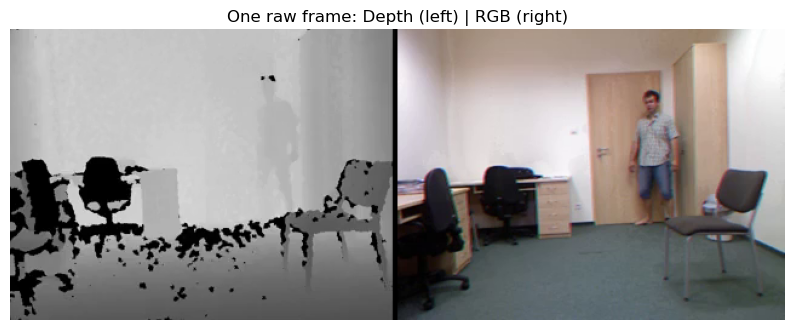

In [4]:
cap = cv2.VideoCapture(os.path.join("urfd_videos", "fall-01-cam0.mp4"))
ok, frame = cap.read()
cap.release()

plt.figure(figsize=(10, 4))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title("One raw frame: Depth (left) | RGB (right)")
plt.axis("off")
plt.show()

### 1.3 Fall vs Normal Activity — Visual Comparison

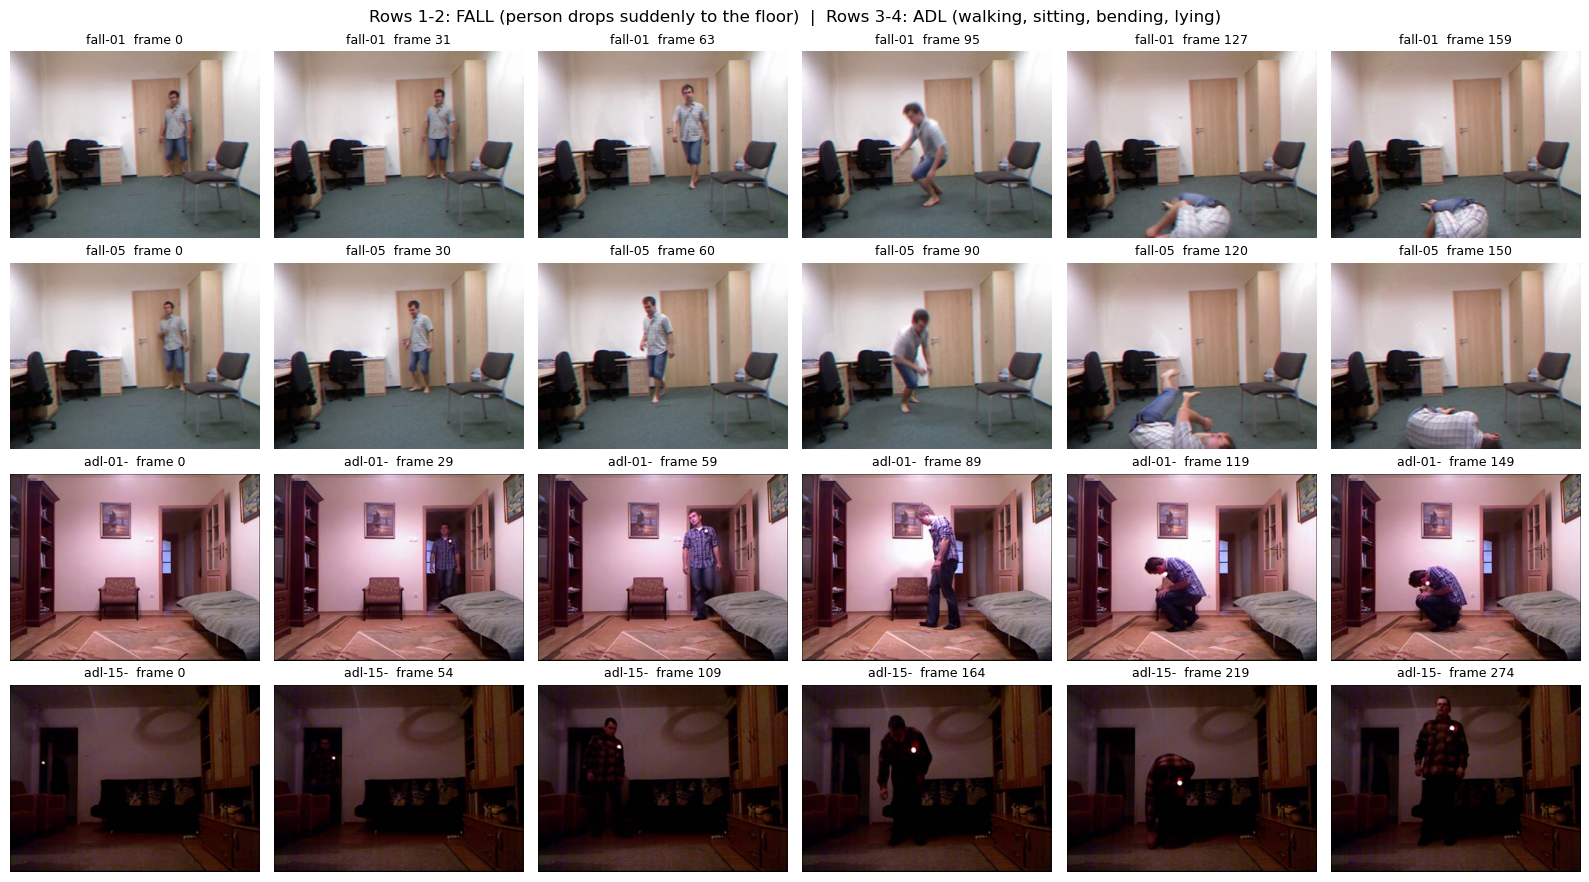

In [5]:
fig, axes = plt.subplots(4, 6, figsize=(16, 9))
for row, name in enumerate(["fall-01-cam0.mp4", "fall-05-cam0.mp4", "adl-01-cam0.mp4", "adl-15-cam0.mp4"]):
    cap = cv2.VideoCapture(os.path.join("urfd_videos", name))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for col, idx in enumerate(np.linspace(0, total - 1, 6).astype(int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        axes[row, col].imshow(cv2.cvtColor(frame[:, 320:], cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"{name[:7]}  frame {idx}", fontsize=9)
        axes[row, col].axis("off")
    cap.release()
plt.suptitle("Rows 1-2: FALL (person drops suddenly to the floor)  |  Rows 3-4: ADL (walking, sitting, bending, lying)")
plt.tight_layout()
plt.show()

**Observation:** in a **fall** the person goes from standing to lying on the floor **within about 1 second** (fast, sudden downward motion).
In **ADL** the movements are slower and controlled — walking, sitting down, picking something up, lying on a bed or sofa.
Some ADL (lying down, crouching) end in a pose similar to a fall, so the **speed of the motion over time** is the key clue — this is why we need a model that looks at **time**, i.e. a **3D CNN**.

### 1.4 Class Distribution

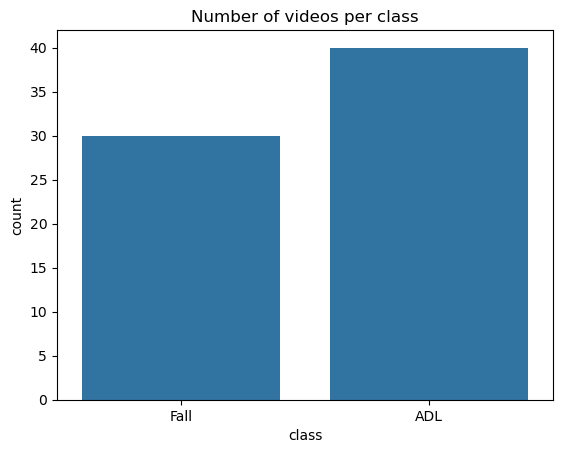

In [6]:
sns.countplot(x="class", data=info_df)
plt.title("Number of videos per class")
plt.show()

---
## Task 2 — Data Preprocessing

### 2.1 Read Videos, Remove Corrupted Files, Crop RGB, Resize
For every video: read all frames → keep the RGB half → convert BGR to RGB → resize.
Frames are stored at 128 × 128 so we can **randomly crop 112 × 112** later (augmentation).
A video that cannot be opened or has fewer than 16 frames is treated as **corrupted** and removed.

In [7]:
NUM_FRAMES = 16
IMG_SIZE = 112
STORE_SIZE = 128

videos = []
labels = []
names = []
for name, label in zip(video_files, video_labels):
    cap = cv2.VideoCapture(os.path.join("urfd_videos", name))
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        rgb = cv2.cvtColor(frame[:, 320:], cv2.COLOR_BGR2RGB)
        frames.append(cv2.resize(rgb, (STORE_SIZE, STORE_SIZE)))
    cap.release()

    if len(frames) < NUM_FRAMES:
        print("Removed corrupted video:", name)
        continue
    videos.append(np.array(frames, dtype=np.uint8))
    labels.append(label)
    names.append(name)

labels = np.array(labels)
print("Usable videos:", len(videos), "| corrupted removed:", len(video_files) - len(videos))

Usable videos: 70 | corrupted removed: 0


### 2.2 Train / Validation / Test Split (70 / 15 / 15, stratified, by video)

In [8]:
idx = np.arange(len(videos))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=42)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=labels[idx_temp], random_state=42)

print("Train:", len(idx_train), "videos | falls:", labels[idx_train].sum())
print("Val  :", len(idx_val), "videos | falls:", labels[idx_val].sum())
print("Test :", len(idx_test), "videos | falls:", labels[idx_test].sum())

Train: 49 videos | falls: 21
Val  : 10 videos | falls: 4
Test : 11 videos | falls: 5


### 2.3 Build 3D Video Tensors (frames × height × width × channels)
- **16 frames** are picked evenly across the whole video (`np.linspace`).
- Validation / test clips use a **center crop** (no augmentation).
- Pixels are **normalized to [0, 1]** by dividing by 255.

In [9]:
X_val, y_val = [], []
for i in idx_val:
    pick = np.linspace(0, len(videos[i]) - 1, NUM_FRAMES).astype(int)
    X_val.append(videos[i][pick, 8:120, 8:120] / 255.0)
    y_val.append(labels[i])

X_test, y_test = [], []
for i in idx_test:
    pick = np.linspace(0, len(videos[i]) - 1, NUM_FRAMES).astype(int)
    X_test.append(videos[i][pick, 8:120, 8:120] / 255.0)
    y_test.append(labels[i])

X_val = np.array(X_val, dtype="float32")
X_test = np.array(X_test, dtype="float32")
y_val = np.array(y_val)
y_test = np.array(y_test)
print("Val tensor :", X_val.shape)
print("Test tensor:", X_test.shape)

Val tensor : (10, 16, 112, 112, 3)
Test tensor: (11, 16, 112, 112, 3)


### 2.4 Data Augmentation (training set only)
Each training video gives **1 original clip + 4 augmented clips**. Each augmented clip uses:
- **Temporal jittering** — the start and end frame are shifted randomly, so the 16 frames are sampled differently each time.
- **Random cropping** — a random 112 × 112 window out of the 128 × 128 frame.
- **Random rotation** — the whole clip is rotated by a random angle between −10° and +10°.
- **Random horizontal flip** — 50% chance the clip is mirrored left-right.

The same crop / rotation / flip is applied to **all 16 frames of a clip**, so the motion stays consistent.

In [10]:
N_AUG = 4
X_train, y_train = [], []

for i in idx_train:
    T = len(videos[i])

    pick = np.linspace(0, T - 1, NUM_FRAMES).astype(int)
    X_train.append(videos[i][pick, 8:120, 8:120] / 255.0)
    y_train.append(labels[i])

    for a in range(N_AUG):
        start = np.random.randint(0, T // 5 + 1)
        end = np.random.randint(T - T // 5, T + 1)
        pick = np.linspace(start, end - 1, NUM_FRAMES).astype(int)

        top = np.random.randint(0, STORE_SIZE - IMG_SIZE + 1)
        left = np.random.randint(0, STORE_SIZE - IMG_SIZE + 1)
        clip = videos[i][pick, top:top + IMG_SIZE, left:left + IMG_SIZE]

        angle = np.random.uniform(-10, 10)
        M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), angle, 1.0)
        clip = np.array([cv2.warpAffine(f, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT) for f in clip])

        if np.random.rand() < 0.5:
            clip = clip[:, :, ::-1]

        X_train.append(clip / 255.0)
        y_train.append(labels[i])

X_train = np.array(X_train, dtype="float32")
y_train = np.array(y_train)
print("Train tensor:", X_train.shape)
print("Pixel range :", X_train.min(), "to", X_train.max())

Train tensor: (245, 16, 112, 112, 3)
Pixel range : 0.0 to 1.0


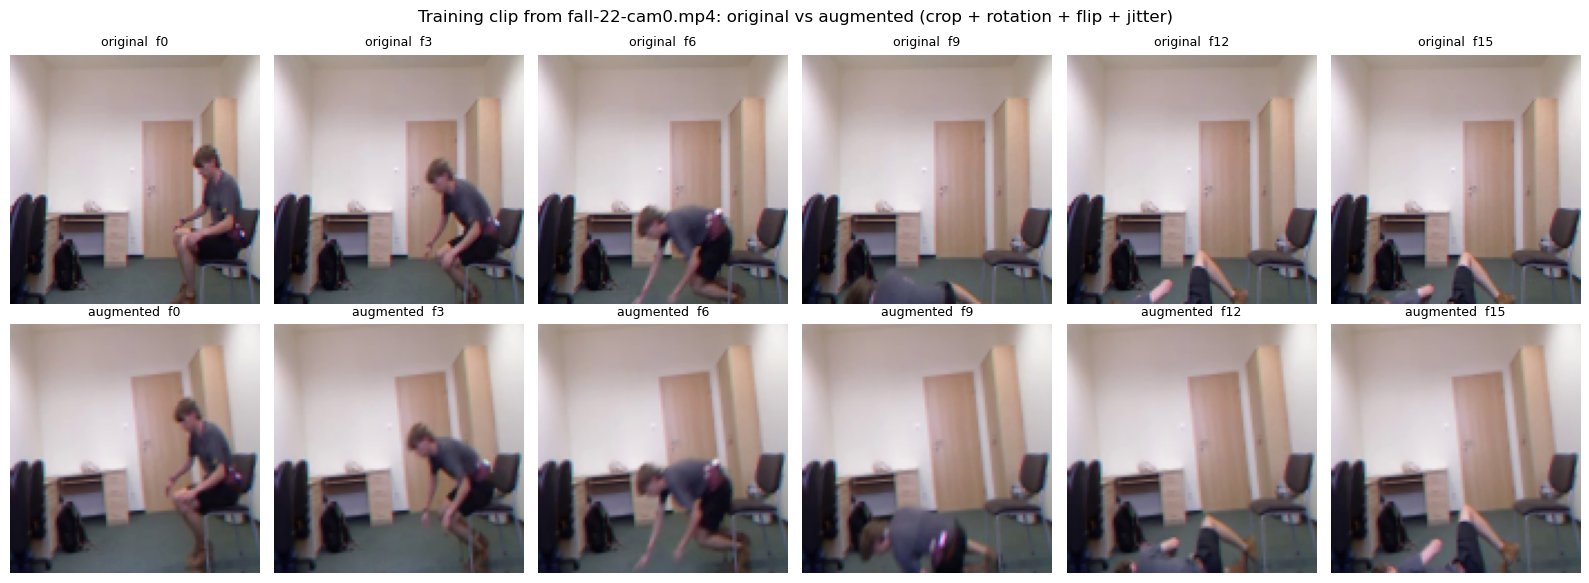

In [11]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for col in range(6):
    axes[0, col].imshow(X_train[0][col * 3])
    axes[0, col].set_title(f"original  f{col * 3}", fontsize=9)
    axes[1, col].imshow(X_train[1][col * 3])
    axes[1, col].set_title(f"augmented  f{col * 3}", fontsize=9)
    axes[0, col].axis("off")
    axes[1, col].axis("off")
plt.suptitle(f"Training clip from {names[idx_train[0]]}: original vs augmented (crop + rotation + flip + jitter)")
plt.tight_layout()
plt.show()

### 2.5 Handle Class Imbalance (weighted loss)
There are more ADL clips than fall clips, so we give the **fall class a higher weight** in the loss.
Missing a fall then costs the model more.

In [12]:
weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: weights[0], 1: weights[1]}
print("Train clips -> ADL:", (y_train == 0).sum(), "| Fall:", (y_train == 1).sum())
print("Class weights:", {k: round(v, 3) for k, v in class_weight.items()})

Train clips -> ADL: 140 | Fall: 105
Class weights: {0: np.float64(0.875), 1: np.float64(1.167)}


---
## Task 3 — Model Training and Basic Evaluation

### 3.1 3D CNN Architecture
A **3D convolution** slides a 3 × 3 × 3 filter over **time + height + width**, so it learns **motion** (how pixels change across frames), not just shapes.

In [13]:
model = models.Sequential([
    layers.Input((NUM_FRAMES, IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv3D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling3D((1, 2, 2)),
    layers.Conv3D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling3D((2, 2, 2)),
    layers.Conv3D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling3D((2, 2, 2)),
    layers.Conv3D(128, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling3D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 16, 112, 112,   │         1,312 │
│                                 │ 16)                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 16, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 16, 56, 56, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 8, 28, 28, 32)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 8, 28, 28, 64)  │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 4, 14, 14, 64)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_3 (Conv3D)               │ (None, 4, 14, 14, 128) │       221,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 300,161 (1.15 MB)

 Trainable params: 300,161 (1.15 MB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Training (with Early Stopping)

In [14]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40, batch_size=8,
    class_weight=class_weight,
    callbacks=[early_stop], verbose=2
)

Epoch 1/40


31/31 - 6s - 209ms/step - accuracy: 0.4694 - loss: 0.6916 - val_accuracy: 0.4000 - val_loss: 0.6941


Epoch 2/40


31/31 - 5s - 160ms/step - accuracy: 0.5429 - loss: 0.6784 - val_accuracy: 0.6000 - val_loss: 0.6728


Epoch 3/40


31/31 - 5s - 159ms/step - accuracy: 0.7061 - loss: 0.6251 - val_accuracy: 0.8000 - val_loss: 0.5313


... (70 outputs left out)

Epoch 39/40


31/31 - 5s - 162ms/step - accuracy: 1.0000 - loss: 0.0101 - val_accuracy: 1.0000 - val_loss: 0.0030


Epoch 40/40


31/31 - 5s - 169ms/step - accuracy: 1.0000 - loss: 0.0090 - val_accuracy: 1.0000 - val_loss: 0.0011


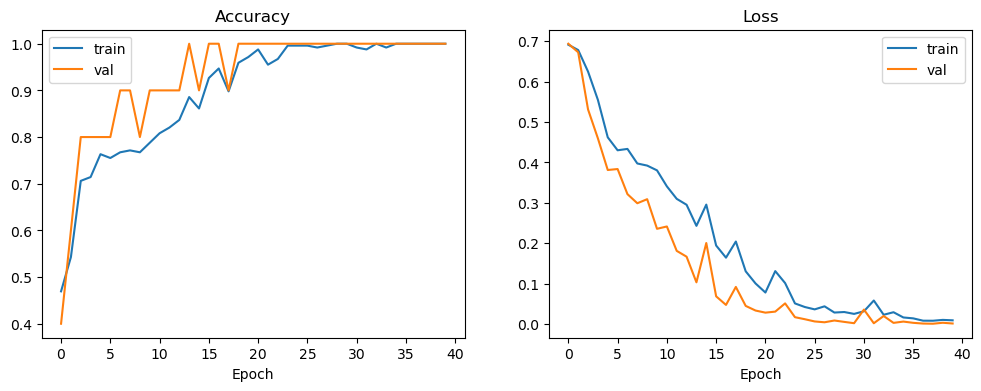

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

### 3.3 Test Set Evaluation — Accuracy, Precision, Recall, F1, AUROC

In [16]:
y_prob = model.predict(X_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("AUROC    :", round(roc_auc_score(y_test, y_prob), 4))
print()
print(classification_report(y_test, y_pred, target_names=["ADL", "Fall"], zero_division=0))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0
AUROC    : 1.0

              precision    recall  f1-score   support

         ADL       1.00      1.00      1.00         6
        Fall       1.00      1.00      1.00         5

    accuracy                           1.00        11
   macro avg       1.00      1.00      1.00        11
weighted avg       1.00      1.00      1.00        11



### 3.4 Confusion Matrix and ROC Curve

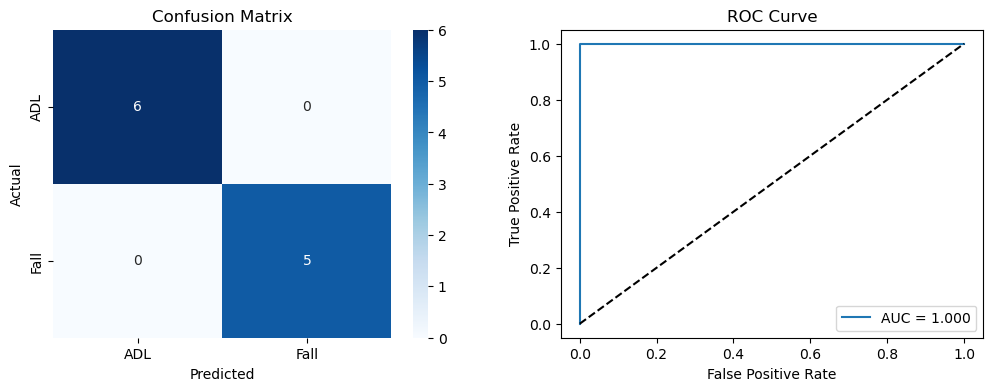

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["ADL", "Fall"], yticklabels=["ADL", "Fall"], ax=ax[0])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Confusion Matrix")
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve"); ax[1].legend()
plt.show()

### 3.5 Per-Video Predictions and Misclassifications

In [18]:
results = pd.DataFrame({
    "video": [names[i] for i in idx_test],
    "actual": ["Fall" if t == 1 else "ADL" for t in y_test],
    "predicted": ["Fall" if p == 1 else "ADL" for p in y_pred],
    "P(fall)": y_prob.round(3),
})
results["correct"] = results["actual"] == results["predicted"]
results

,video,actual,predicted,P(fall),correct
0,adl-11-cam0.mp4,ADL,ADL,0.000,True
1,adl-29-cam0.mp4,ADL,ADL,0.004,True
2,adl-15-cam0.mp4,ADL,ADL,0.000,True
3,fall-28-cam0.mp4,Fall,Fall,1.000,True
4,adl-33-cam0.mp4,ADL,ADL,0.005,True
5,fall-07-cam0.mp4,Fall,Fall,0.993,True
6,fall-04-cam0.mp4,Fall,Fall,0.995,True
7,adl-23-cam0.mp4,ADL,ADL,0.000,True
8,adl-36-cam0.mp4,ADL,ADL,0.000,True
9,fall-14-cam0.mp4,Fall,Fall,1.000,True


Misclassified test videos: 0


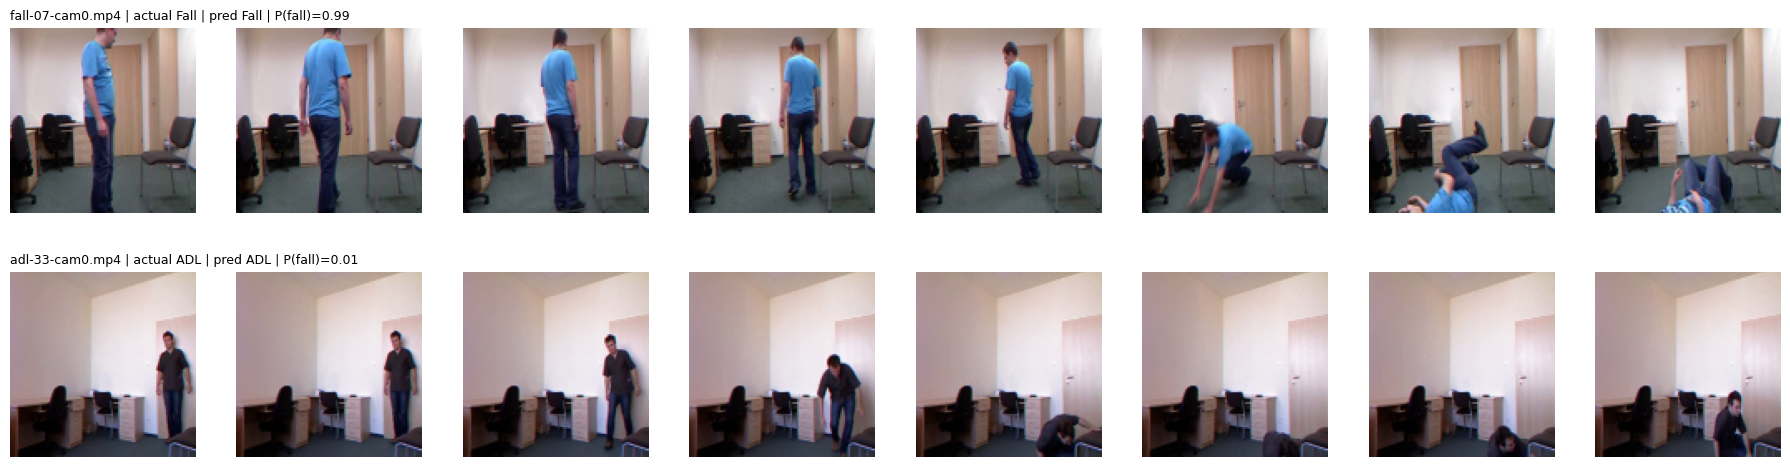

In [19]:
wrong = np.where(y_pred != y_test)[0]
print("Misclassified test videos:", len(wrong))

show = wrong if len(wrong) > 0 else np.argsort(np.abs(y_prob - 0.5))[:2]
fig, axes = plt.subplots(len(show), 8, figsize=(18, 2.6 * len(show)), squeeze=False)
for row, k in enumerate(show):
    for col in range(8):
        axes[row, col].imshow(X_test[k][col * 2])
        axes[row, col].axis("off")
    axes[row, 0].set_title(f"{results.video[k]} | actual {results.actual[k]} | pred {results.predicted[k]} | P(fall)={y_prob[k]:.2f}",
                           fontsize=9, loc="left")
plt.tight_layout()
plt.show()

### 3.6 Robustness Test — Different Camera View (cam1)
The test set above is very small (11 videos). URFD also filmed **every fall with a second camera (cam1)** mounted **high up, looking down**.
The model was trained only on **cam0** (side view), so cam1 tells us how well it handles a **new camera angle** — and gives us real misclassifications to analyse.

In [20]:
cam1_names, X_cam1 = [], []
for i in range(1, 31):
    name = f"fall-{i:02d}-cam1.mp4"
    path = os.path.join("urfd_videos", name)
    if not os.path.exists(path):
        r = requests.get(BASE_URL + name, timeout=120)
        open(path, "wb").write(r.content)

    cap = cv2.VideoCapture(path)
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        rgb = cv2.cvtColor(frame[:, 320:], cv2.COLOR_BGR2RGB)
        frames.append(cv2.resize(rgb, (STORE_SIZE, STORE_SIZE)))
    cap.release()
    if len(frames) < NUM_FRAMES:
        continue
    frames = np.array(frames)
    pick = np.linspace(0, len(frames) - 1, NUM_FRAMES).astype(int)
    X_cam1.append(frames[pick, 8:120, 8:120] / 255.0)
    cam1_names.append(name)

X_cam1 = np.array(X_cam1, dtype="float32")
p_cam1 = model.predict(X_cam1, verbose=0).ravel()
cam1_df = pd.DataFrame({"video": cam1_names, "P(fall)": p_cam1.round(3), "detected": p_cam1 >= 0.5})

print("cam1 fall videos:", len(cam1_names))
print("Falls detected (recall on new camera view):", cam1_df.detected.sum(), "/", len(cam1_df), "=", round(cam1_df.detected.mean(), 3))
cam1_df[~cam1_df.detected]

cam1 fall videos: 30
Falls detected (recall on new camera view): 1 / 30 = 0.033


,video,P(fall),detected
0,fall-01-cam1.mp4,0.192,False
1,fall-02-cam1.mp4,0.007,False
2,fall-03-cam1.mp4,0.145,False
3,fall-04-cam1.mp4,0.089,False
4,fall-05-cam1.mp4,0.144,False
5,fall-06-cam1.mp4,0.088,False
6,fall-07-cam1.mp4,0.154,False
7,fall-08-cam1.mp4,0.470,False
8,fall-09-cam1.mp4,0.203,False
10,fall-11-cam1.mp4,0.139,False


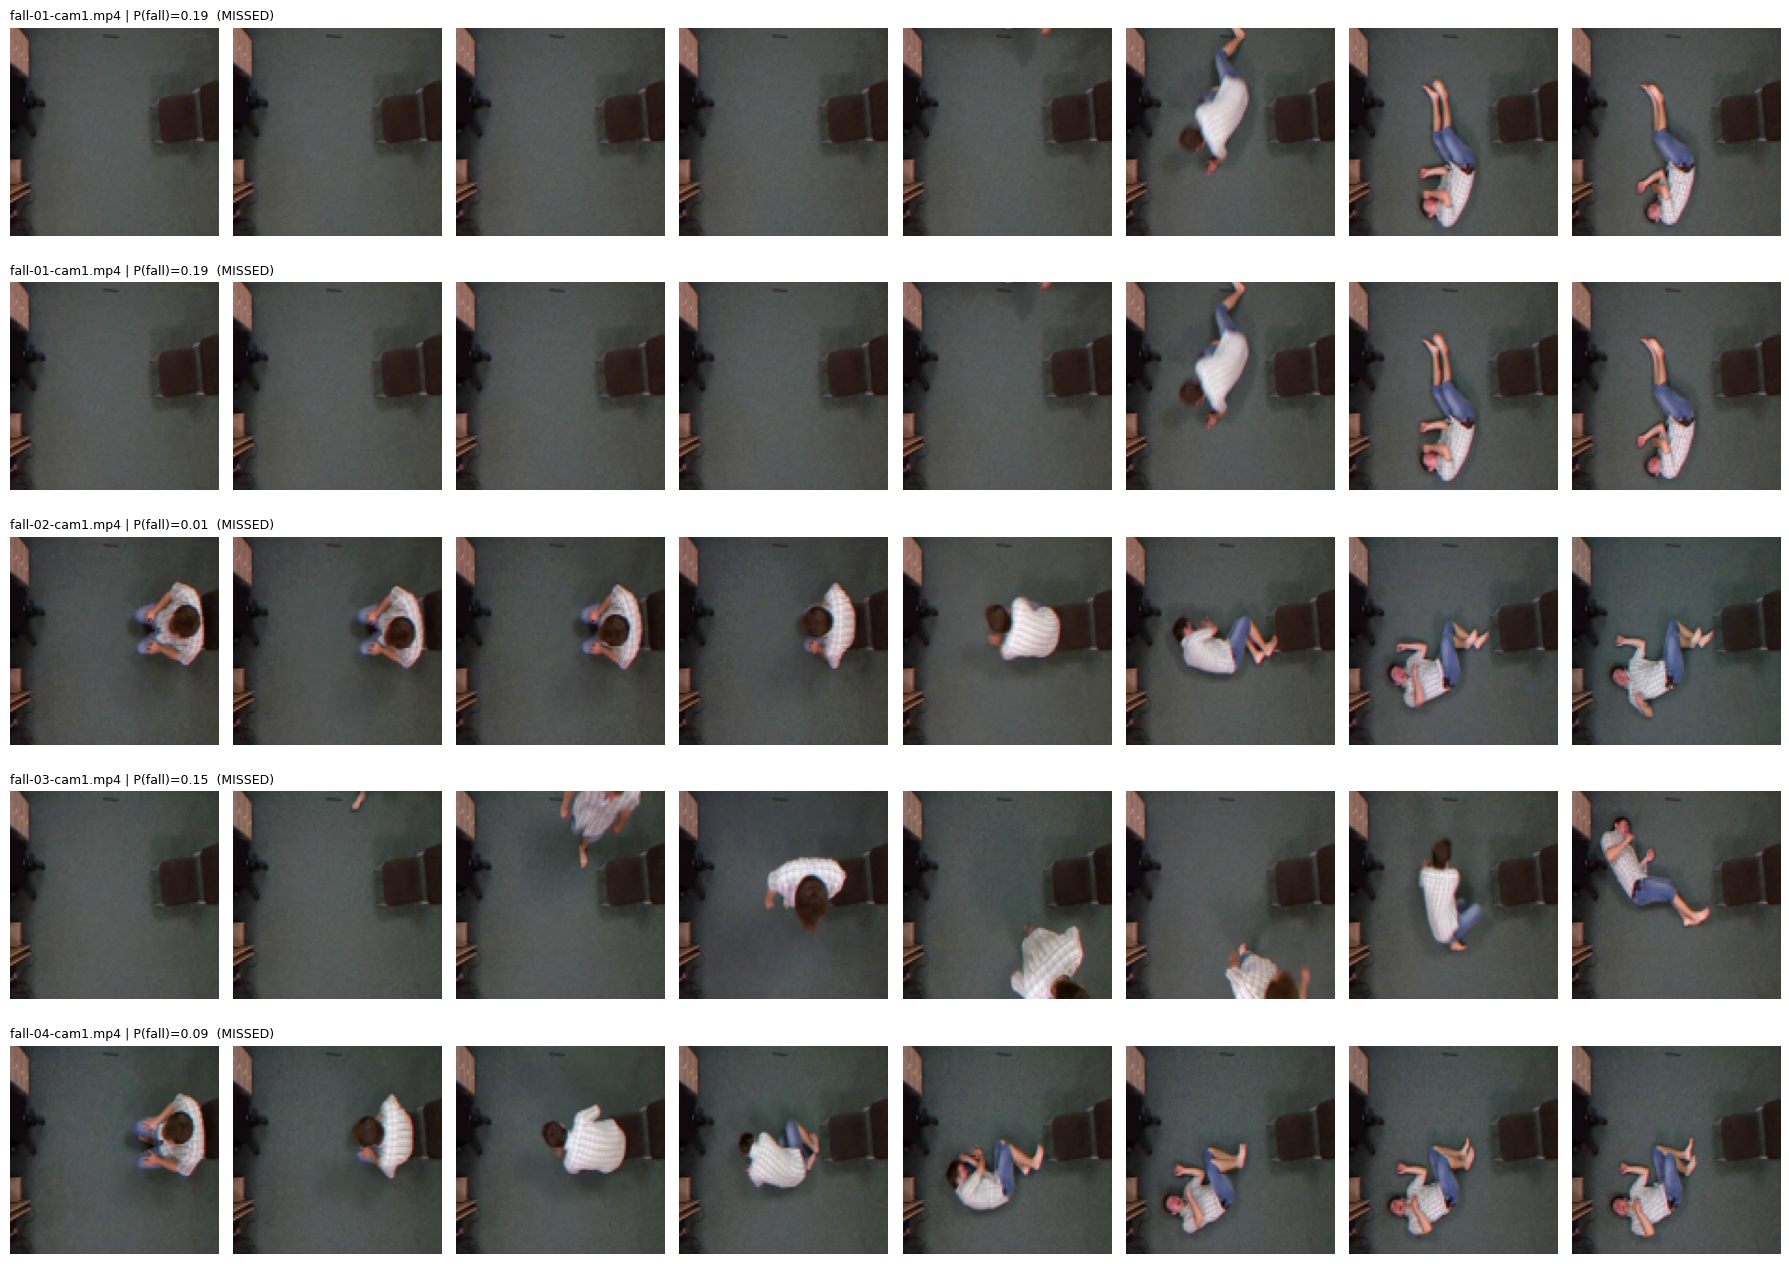

In [21]:
show = list(np.where(p_cam1 >= 0.5)[0][:1]) + list(np.where(p_cam1 < 0.5)[0][:4])
fig, axes = plt.subplots(len(show), 8, figsize=(18, 2.6 * len(show)), squeeze=False)
for row, k in enumerate(show):
    for col in range(8):
        axes[row, col].imshow(X_cam1[k][col * 2])
        axes[row, col].axis("off")
    axes[row, 0].set_title(f"{cam1_names[k]} | P(fall)={p_cam1[k]:.2f}" + ("  (MISSED)" if p_cam1[k] < 0.5 else "  (detected)"),
                           fontsize=9, loc="left")
plt.tight_layout()
plt.show()